# Stage Association 

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal, f as f_dist, rankdata

sns.set_theme(style="whitegrid")
DATA_DIR = "../data"
OUTPUT_DIR = "../results/stage_confounding"
os.makedirs(OUTPUT_DIR, exist_ok=True)

FILES = {
    "TCGA_LUAD_EXPR": "LUAD.csv", "TCGA_LUSC_EXPR": "LUSC.csv",
    "TCGA_LUAD_CLIN": "TCGA_LUAD_sampleMap_LUAD_clinicalMatrix.xlsx",
    "TCGA_LUSC_CLIN": "TCGA_LUSC_sampleMap_LUSC_clinicalMatrix.xlsx",
    "GSE_EXPR": "GSE37745_expression.csv", "GSE_CLIN": "GSE37745_clinical.csv",
}
FILES = {k: os.path.join(DATA_DIR, v) for k, v in FILES.items()}
for k, p in FILES.items():
    print(f"{k:15s} -> {p}  {'OK' if os.path.exists(p) else 'NOT FOUND !!!'}")

TCGA_CORE_STABLE = ["KRT5", "KRT6A", "KRT6B", "KRT6C", "DSG3", "DSC3", "KRT14", "KRT13",
                    "S100A7", "SERPINB13", "CALML3", "CLCA2", "GSTM1", "MUC5B", "SPRR2A"]
MIN_PER_GROUP = 3   # same rule as the original pipeline

def bh_fdr(p):
    p = np.asarray(p, float); n = len(p)
    if n == 0:
        return p
    order = np.argsort(p)
    q = p[order] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(q, 1)
    return out

TCGA_LUAD_EXPR  -> .\LUAD.csv  OK
TCGA_LUSC_EXPR  -> .\LUSC.csv  OK
TCGA_LUAD_CLIN  -> .\TCGA_LUAD_sampleMap_LUAD_clinicalMatrix.xlsx  OK
TCGA_LUSC_CLIN  -> .\TCGA_LUSC_sampleMap_LUSC_clinicalMatrix.xlsx  OK
GSE_EXPR        -> .\GSE37745_expression.csv  OK
GSE_CLIN        -> .\GSE37745_clinical.csv  OK


## 2. Load TCGA — same rules as the original pipeline (Primary Tumor, stage I–IV)

In [2]:
def load_primary_tumor(path):
    e = pd.read_csv(path, index_col=0).T
    e = e[e.index.str.endswith("-01")]
    e.columns = [str(c).split("|")[0].upper() for c in e.columns]
    return e.loc[:, ~e.columns.duplicated()].astype(np.float32)

e_luad, e_lusc = load_primary_tumor(FILES["TCGA_LUAD_EXPR"]), load_primary_tumor(FILES["TCGA_LUSC_EXPR"])
genes = e_luad.columns.intersection(e_lusc.columns)
X_tcga = pd.concat([e_luad[genes], e_lusc[genes]])
hist_tcga = pd.Series(["LUAD"] * len(e_luad) + ["LUSC"] * len(e_lusc), index=X_tcga.index)

def simplify_stage(raw):
    if pd.isna(raw):
        return None
    s = str(raw).upper().replace("STAGE ", "").strip()
    s = re.sub(r"[ABC]$", "", s)
    return s if s in ["I", "II", "III", "IV"] else None

c_luad = pd.read_excel(FILES["TCGA_LUAD_CLIN"]).set_index("sampleID")
c_lusc = pd.read_excel(FILES["TCGA_LUSC_CLIN"]).set_index("sampleID")
stage_tcga = pd.concat([c_luad["pathologic_stage"], c_lusc["pathologic_stage"]]).apply(simplify_stage).dropna()
stage_tcga = stage_tcga[~stage_tcga.index.duplicated()]
idx = X_tcga.index.intersection(stage_tcga.index)

TCGA = {"name": "TCGA", "X": X_tcga.loc[idx], "stage": stage_tcga.loc[idx], "hist": hist_tcga.loc[idx],
        "order": ["I", "II", "III", "IV"]}
print(f"TCGA samples with expression + stage: {len(idx)}")

TCGA samples with expression + stage: 1004


## 3. Load GSE37745 (stage III and IV merged, as in the replication notebook)

In [3]:
X_gse = pd.read_csv(FILES["GSE_EXPR"], index_col=0).T
X_gse.columns = [str(c).upper() for c in X_gse.columns]
X_gse = X_gse.loc[:, ~X_gse.columns.duplicated()]
cg = pd.read_csv(FILES["GSE_CLIN"], index_col=0)
cg = cg[cg["histology"].isin(["LUAD", "LUSC"]) & cg["stage"].notna()]
stage_gse = cg["stage"].replace({"III": "III/IV", "IV": "III/IV"})

GSE = {"name": "GSE37745", "X": X_gse.loc[cg.index].astype(np.float32), "stage": stage_gse,
       "hist": cg["histology"], "order": ["I", "II", "III/IV"]}
print(f"GSE37745 samples with expression + stage: {len(cg)}")

GSE37745 samples with expression + stage: 172


## 4. The key check — does the LUSC share change across stage?



=== TCGA: histology mix by stage ===
col_0             LUAD  LUSC    n  LUSC_%
pathologic_stage                         
I                  275   244  519    47.0
II                 122   162  284    57.0
III                 84    84  168    50.0
IV                  26     7   33    21.2
Chi-square test (is histology mix different across stages?): p = 0.000377

=== GSE37745: histology mix by stage ===
histology  LUAD  LUSC    n  LUSC_%
stage                             
I            70    40  110    36.4
II           19    15   34    44.1
III/IV       17    11   28    39.3
Chi-square test (is histology mix different across stages?): p = 0.715


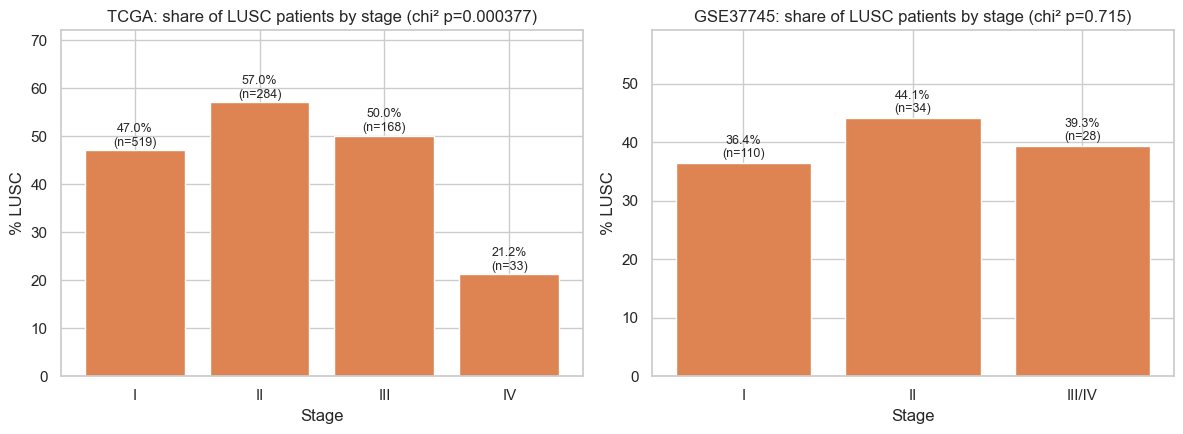

In [4]:
comp_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, C in zip(axes, [TCGA, GSE]):
    ct = pd.crosstab(C["stage"], C["hist"]).reindex(C["order"])
    ct["n"] = ct.sum(axis=1)
    ct["LUSC_%"] = (ct["LUSC"] / ct["n"] * 100).round(1)
    print(f"\n=== {C['name']}: histology mix by stage ===")
    print(ct.to_string())
    from scipy.stats import chi2_contingency
    chi2, p, _, _ = chi2_contingency(ct[["LUAD", "LUSC"]].values)
    print(f"Chi-square test (is histology mix different across stages?): p = {p:.3g}")
    comp_rows.append({"cohort": C["name"], "chi2_p_histology_vs_stage": p,
                      **{f"LUSC_%_stage_{s}": v for s, v in ct["LUSC_%"].items()}})
    ax.bar(ct.index, ct["LUSC_%"], color="#DD8452")
    for i, (v, n) in enumerate(zip(ct["LUSC_%"], ct["n"])):
        ax.text(i, v + 1, f"{v}%\n(n={n})", ha="center", fontsize=9)
    ax.set_ylim(0, max(ct["LUSC_%"]) + 15); ax.set_ylabel("% LUSC"); ax.set_xlabel("Stage")
    ax.set_title(f"{C['name']}: share of LUSC patients by stage (chi² p={p:.3g})")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/lusc_share_by_stage.png", dpi=150); plt.show()
pd.DataFrame(comp_rows).to_csv(f"{OUTPUT_DIR}/histology_mix_by_stage.csv", index=False)

## 5. Run the three tests for every TCGA core-stable gene in both cohorts

In [5]:
def kw(values, stages, order):
    groups = [values[stages == s] for s in order]
    groups = [g for g in groups if len(g) >= MIN_PER_GROUP]
    if len(groups) < 2:
        return np.nan
    return kruskal(*groups).pvalue

def adjusted_stage_p(values, stages, hist, order):
    """Rank-based linear model: rank(expr) ~ histology + stage. F-test for the stage term."""
    keep = stages.isin(order).values
    yv = rankdata(values[keep]); st = stages[keep].values; h = (hist[keep].values == "LUSC").astype(float)
    levels = [s for s in order if (st == s).sum() >= MIN_PER_GROUP]
    m = np.isin(st, levels); yv, st, h = yv[m], st[m], h[m]
    X_red = np.column_stack([np.ones(len(yv)), h])
    X_full = np.column_stack([X_red] + [(st == s).astype(float) for s in levels[1:]])
    rss = lambda Xm: np.sum((yv - Xm @ np.linalg.lstsq(Xm, yv, rcond=None)[0]) ** 2)
    rss_r, rss_f = rss(X_red), rss(X_full)
    df1, df2 = X_full.shape[1] - X_red.shape[1], len(yv) - X_full.shape[1]
    F = ((rss_r - rss_f) / df1) / (rss_f / df2)
    return float(1 - f_dist.cdf(F, df1, df2))

all_results = {}
for C in [TCGA, GSE]:
    rows = []
    for g in TCGA_CORE_STABLE:
        if g not in C["X"].columns:
            continue
        v = C["X"][g].values; st = C["stage"].values; hs = C["hist"].values
        r = {"gene": g,
             "pooled_p": kw(v, st, C["order"]),
             "LUAD_only_p": kw(v[hs == "LUAD"], st[hs == "LUAD"], C["order"]),
             "LUSC_only_p": kw(v[hs == "LUSC"], st[hs == "LUSC"], C["order"]),
             "hist_adjusted_p": adjusted_stage_p(C["X"][g], C["stage"], C["hist"], C["order"])}
        for s in C["order"]:
            r[f"mean_{s}"] = float(np.mean(v[st == s])) if (st == s).sum() else np.nan
        rows.append(r)
    df = pd.DataFrame(rows)
    for col in ["pooled_p", "LUAD_only_p", "LUSC_only_p", "hist_adjusted_p"]:
        df[col.replace("_p", "_fdr")] = bh_fdr(df[col].fillna(1).values)
    df = df.sort_values("pooled_p").reset_index(drop=True)
    all_results[C["name"]] = df
    df.to_csv(f"{OUTPUT_DIR}/stage_tests_{C['name']}.csv", index=False)
    show = ["gene", "pooled_p", "LUAD_only_p", "LUSC_only_p", "hist_adjusted_p", "hist_adjusted_fdr"]
    print(f"\n=== {C['name']} (n={len(C['stage'])}) ===")
    print(df[show].round(4).to_string(index=False))


=== TCGA (n=1004) ===
     gene  pooled_p  LUAD_only_p  LUSC_only_p  hist_adjusted_p  hist_adjusted_fdr
    KRT6C    0.0026       0.0004       0.6993           0.0192             0.1440
   SPRR2A    0.0029       0.7556       0.0811           0.4979             0.9436
     DSG3    0.0031       0.4914       0.8613           0.9630             0.9862
    KRT6A    0.0034       0.0002       0.6635           0.0099             0.1440
    KRT14    0.0036       0.0329       0.8439           0.6323             0.9436
     DSC3    0.0055       0.7285       0.7724           0.9862             0.9862
    KRT6B    0.0057       0.0024       0.7711           0.1319             0.6597
     KRT5    0.0064       0.8426       0.7777           0.9642             0.9862
   CALML3    0.0182       0.9104       0.7691           0.7119             0.9436
SERPINB13    0.0238       0.9992       0.2425           0.5046             0.9436
    MUC5B    0.0398       0.0900       0.0079           0.5980             

## 6. Summary — how many genes stay stage-associated after removing histology?

In [6]:
summary = []
for name, df in all_results.items():
    n = len(df)
    summary.append({
        "cohort": name, "genes_tested": n,
        "pooled p<0.05 (original method)": f"{(df.pooled_p < .05).sum()}/{n}",
        "pooled FDR<0.05": f"{(df.pooled_fdr < .05).sum()}/{n}",
        "LUAD-only p<0.05": f"{(df.LUAD_only_p < .05).sum()}/{n}",
        "LUSC-only p<0.05": f"{(df.LUSC_only_p < .05).sum()}/{n}",
        "histology-adjusted p<0.05": f"{(df.hist_adjusted_p < .05).sum()}/{n}",
        "histology-adjusted FDR<0.05": f"{(df.hist_adjusted_fdr < .05).sum()}/{n}",
        "genes adjusted FDR<0.05": ", ".join(df.loc[df.hist_adjusted_fdr < .05, "gene"]) or "none",
    })
summary_df = pd.DataFrame(summary).set_index("cohort").T
print(summary_df.to_string())
summary_df.to_csv(f"{OUTPUT_DIR}/stage_confounding_summary.csv")

cohort                            TCGA GSE37745
genes_tested                        15       13
pooled p<0.05 (original method)  11/15     1/13
pooled FDR<0.05                  10/15     0/13
LUAD-only p<0.05                  4/15     1/13
LUSC-only p<0.05                  1/15     2/13
histology-adjusted p<0.05         2/15     2/13
histology-adjusted FDR<0.05       0/15     1/13
genes adjusted FDR<0.05           none   S100A7


## 7. Visual — pooled vs within-histology means across stage (top 6 genes by pooled p in TCGA)

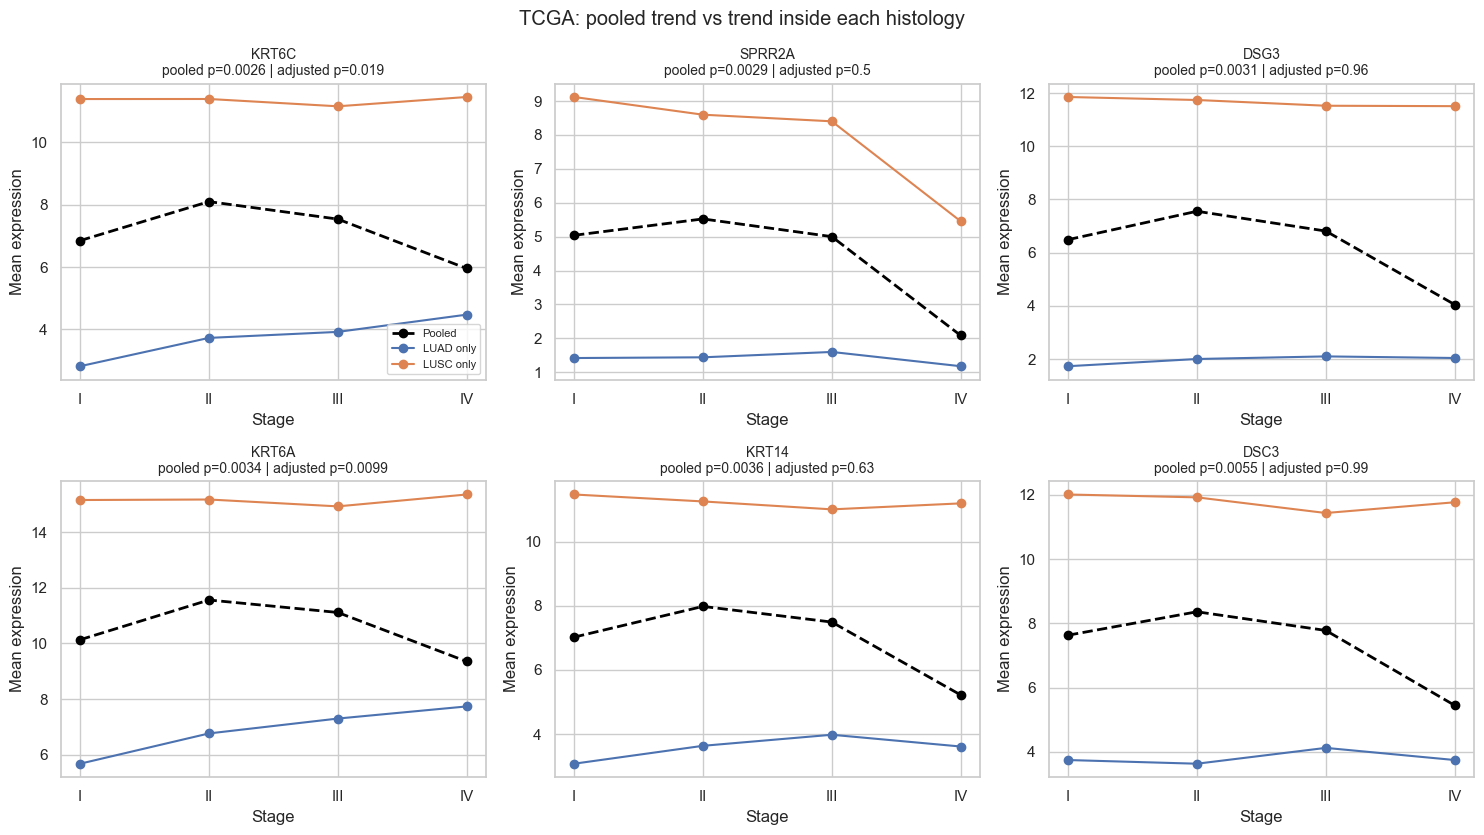

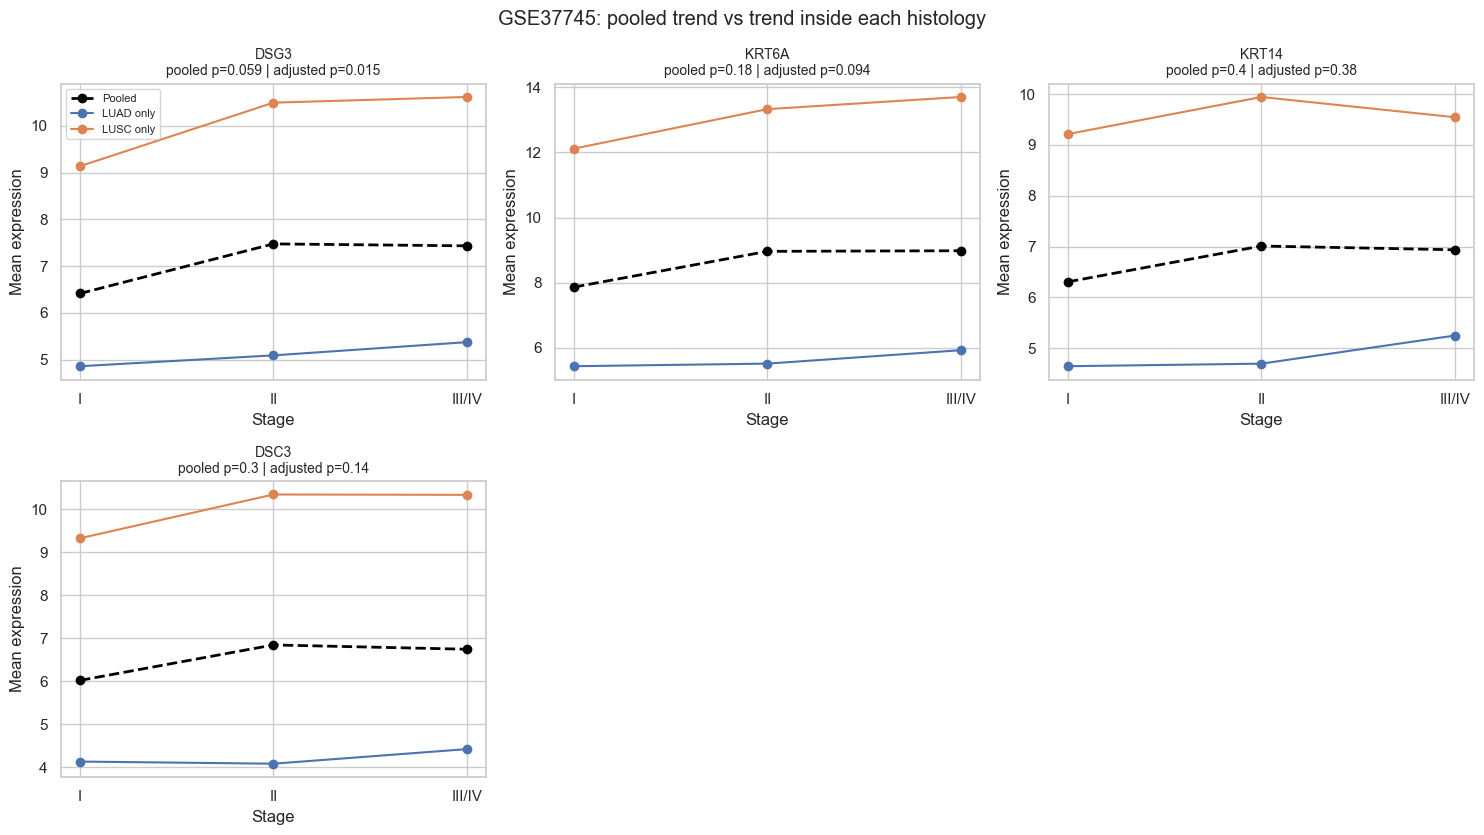

All outputs saved in: results_stage_confounding/


In [7]:
top6 = all_results["TCGA"].head(6)["gene"].tolist()
for C in [TCGA, GSE]:
    genes_here = [g for g in top6 if g in C["X"].columns]
    fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
    for ax, g in zip(axes.flatten(), genes_here):
        for label, mask, col in [("Pooled", np.ones(len(C["hist"]), bool), "black"),
                                 ("LUAD only", (C["hist"] == "LUAD").values, "#4C72B0"),
                                 ("LUSC only", (C["hist"] == "LUSC").values, "#DD8452")]:
            means = [C["X"].loc[mask & (C["stage"] == s).values, g].mean() for s in C["order"]]
            ax.plot(C["order"], means, "o-", color=col, label=label, lw=2 if label == "Pooled" else 1.5,
                    ls="--" if label == "Pooled" else "-")
        p = all_results[C["name"]].set_index("gene").loc[g]
        ax.set_title(f"{g}\npooled p={p.pooled_p:.2g} | adjusted p={p.hist_adjusted_p:.2g}", fontsize=10)
        ax.set_xlabel("Stage"); ax.set_ylabel("Mean expression")
    for ax in axes.flatten()[len(genes_here):]:
        ax.axis("off")
    axes.flatten()[0].legend(fontsize=8)
    plt.suptitle(f"{C['name']}: pooled trend vs trend inside each histology")
    plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/stage_trends_{C['name']}.png", dpi=150); plt.show()
print(f"All outputs saved in: {OUTPUT_DIR}/")